In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[0.0009479650312997711 + 0.0016518173510914173im -0.001457077032774588 - 0.0016779473763883438im … 0.0017082918016104235 - 0.0005078261517768653im -0.0032437003063431097 + 0.0008634287832232032im; 0.0024285124861603952 - 0.00021278681224573125im 0.0013895629364465674 + 0.0017020258516983087im … -0.0012008021164835352 + 0.003338587361566534im 1.6018828670093707e-5 + 0.00199848187217177im; -0.0033639266522405425 + 0.002194320617140101im -0.0006029966972789611 - 0.005367285301283019im … -0.0019140917440065102 + 8.870425593603023e-6im -0.002724517328877245 + 0.0008561482598677777im;;; 6.981101907150433e-5 + 0.001969551703383958im -0.001200007853106423 + 0.002627436381096592im … 0.000895893226308831 - 0.0025045100923730365im -0.001974918368192634 - 0.00010663376854836039im; -0.0035338311361888504 + 0.0005821251462743493im -0.00020670799055680497 - 0.0010121803264538862im … 0.005106154712425495 - 0.0007665610212293183

In [3]:
P=Onestep()
hop=Hopping_operator(U,P)
W1=Generate_weight(hop)
W2=Generate_weight(hop)

9-element Vector{Spin_matrix}:
 [-0.027820888396720176 + 0.0im 1.180014835391425 + 0.0im 0.34436990666618345 + 0.0im -1.5706893294767836 + 0.0im; 0.264166179364126 + 0.0im 1.675050519206308 + 0.0im 1.368442060412607 + 0.0im 0.1821487003961809 + 0.0im; -0.6447565661386178 + 0.0im -0.4687342051712926 + 0.0im -1.2140097157135243 + 0.0im -0.009513198640857212 + 0.0im; 1.4530595211549164 + 0.0im 1.1236079876046547 + 0.0im -0.056000298260902706 + 0.0im 0.8796361783685798 + 0.0im]
 [0.5645963311320605 + 0.0im -0.5108172994885967 + 0.0im 0.5399873761173319 + 0.0im -1.0133469467429967 + 0.0im; 1.9315164170769423 + 0.0im -0.9313722046623805 + 0.0im 1.0253604810161006 + 0.0im 2.3873205248175284 + 0.0im; -1.0932974281577292 + 0.0im -0.47687891781950914 + 0.0im 0.42348207259534576 + 0.0im -1.6281416353475824 + 0.0im; 0.29563652800870904 + 0.0im 0.9629062834693953 + 0.0im 0.5255670068393108 + 0.0im 0.3329546152410405 + 0.0im]
 [-0.30714462371468865 + 0.0im -1.7035156939091678 + 0.0im -0.951387831708

In [4]:
layer1=CPTC_Layer(hop,W1)
Norm=complexNormLayer()
layer2=PTC_Layer(hop,W2)
act=Softmax()
layer1=Attention_Layer(layer1,sqrt(length(x)) , act,true)
layers=[layer1,Norm,layer2]

3-element Vector{LMP.Layer_types.Layer}:
 Attention_Layer(CPTC_Layer(Spin_matrix[[-0.012378918938037508 + 0.0im 0.15453812761117774 + 0.0im -0.5797580269048666 + 0.0im -0.28830425251256964 + 0.0im; -0.25942341997742374 + 0.0im 1.6738374771348195 + 0.0im 1.9750811038214193 + 0.0im -1.2530995446055757 + 0.0im; 1.28159421652032 + 0.0im 0.9014241574325572 + 0.0im -1.0869304508787236 + 0.0im -0.7008878724998261 + 0.0im; 1.4977697622177175 + 0.0im 0.9099800738370094 + 0.0im -1.6419732266194078 + 0.0im -1.0982174157749993 + 0.0im], [-0.12015513767596364 + 0.0im -0.2168999084086542 + 0.0im 0.6058463730313268 + 0.0im -1.7432945059212015 + 0.0im; -0.5458936226863994 + 0.0im 0.4022733393474853 + 0.0im -0.17305834267839942 + 0.0im 0.32136729295199895 + 0.0im; 0.43764450871555594 + 0.0im -1.3807617181994365 + 0.0im -0.4017113948079746 + 0.0im 1.05063673087235 + 0.0im; -1.0604230141529458 + 0.0im 0.48126051423820343 + 0.0im -1.4118803721014372 + 0.0im 0.2193226501640648 + 0.0im], [1.718740027795537 

In [5]:
opt=Adam()
opt.α=0.05

0.05

In [6]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3
params["mass"] = 0.1

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[5.819073480853973e-6 + 6.76987493683048e-6im 2.037112611208994e-6 + 1.1874186251876491e-5im … -1.099487961517244e-7 + 2.139933933617055e-5im 4.245321215120454e-6 + 4.050444376227351e-7im; -3.6981954580503767e-6 - 2.714519295513615e-6im 9.245759314004021e-6 - 1.1638959832612658e-5im … -6.763030293123138e-6 + 9.51061779155673e-7im 1.0767519206024468e-5 + 1.0933080190033062e-5im; 5.696079469581208e-6 - 2.0379410061044496e-6im -1.8517795013543583e-5 + 4.659242317029256e-6im … 2.4171810132375025e-7 + 7.694362260518602e-7im -2.3970475660546985e-6 - 9.956985695641337e-7im;;; 5.128223483242076e-6 + 1.5095754105382091e-5im -3.1957445834813123e-6 - 6.4897785461286575e-6im … -1.3402400362038839e-6 + 7.510117150462701e-6im 1.2798231523093878e-6 - 3.890363259816755e-6im; -4.935904066254554e-6 - 1.0643636502009128e-6im -1.443876250582344e-6 - 2.2793603110300623e-6im … -2.767325787583852e-7 - 3.885235614795185e-6im -1.4266103

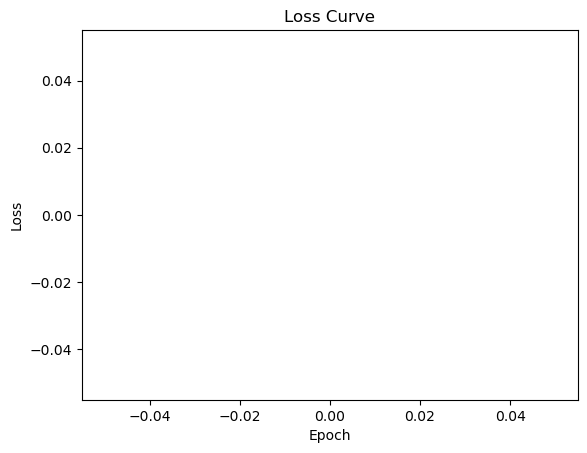

Epoch: 1, Loss: 1553.9943470165242 + 0.0im
Epoch: 2, Loss: 1214.4319574478448 + 0.0im
Epoch: 3, Loss: 954.1417227234401 + 0.0im
Epoch: 4, Loss: 766.0993619946908 + 0.0im
Epoch: 5, Loss: 604.7521009314278 + 0.0im
Epoch: 6, Loss: 475.0061693216586 + 0.0im
Epoch: 7, Loss: 375.7857219007286 + 0.0im
Epoch: 8, Loss: 294.72333943944454 + 0.0im
Epoch: 9, Loss: 228.89021788853717 + 0.0im
Epoch: 10, Loss: 183.07892942634825 + 0.0im
Epoch: 11, Loss: 145.05974579491328 + 0.0im
Epoch: 12, Loss: 116.19190482386486 + 0.0im
Epoch: 13, Loss: 94.19182484686308 + 0.0im
Epoch: 14, Loss: 78.5812846052805 + 0.0im
Epoch: 15, Loss: 66.92185221953414 + 0.0im
Epoch: 16, Loss: 57.56615570555418 + 0.0im
Epoch: 17, Loss: 50.74989606827306 + 0.0im
Epoch: 18, Loss: 45.3091740816249 + 0.0im
Epoch: 19, Loss: 40.815794664786466 + 0.0im
Epoch: 20, Loss: 37.46706077193981 + 0.0im
Epoch: 21, Loss: 34.74224943690483 + 0.0im
Epoch: 22, Loss: 32.8065233400921 + 0.0im
Epoch: 23, Loss: 30.634212657427547 + 0.0im
Epoch: 24, Los

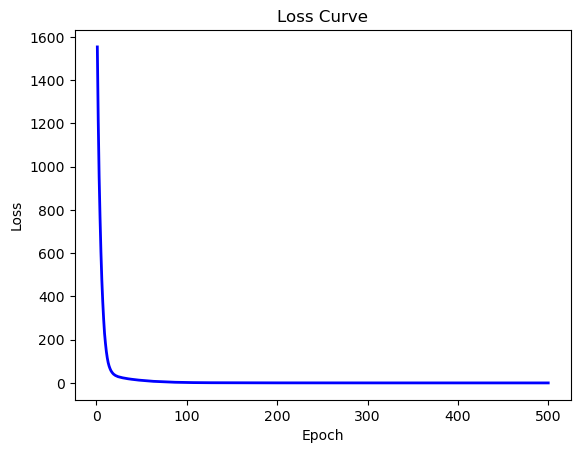

In [7]:
train(opt,layers,x,t,D,epochs=500)

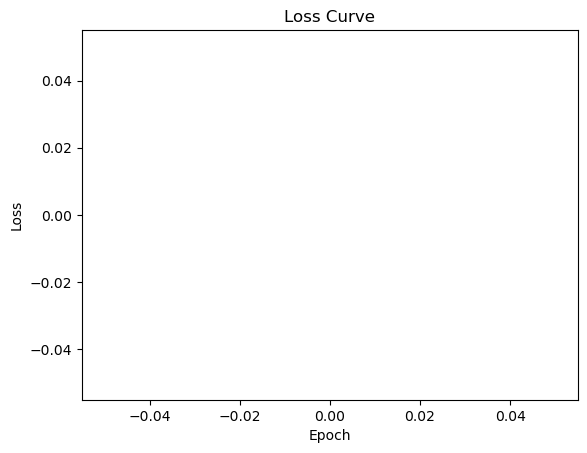

Epoch: 1, Loss: 0.25192769855950065 + 0.0im
Epoch: 2, Loss: 0.25034036158932005 + 0.0im
Epoch: 3, Loss: 0.25151406950362787 + 0.0im
Epoch: 4, Loss: 0.24925388231820905 + 0.0im
Epoch: 5, Loss: 0.2498176061241963 + 0.0im
Epoch: 6, Loss: 0.24982882365975734 + 0.0im
Epoch: 7, Loss: 0.2514584034521539 + 0.0im
Epoch: 8, Loss: 0.24908348459047927 + 0.0im
Epoch: 9, Loss: 0.24916978735895237 + 0.0im
Epoch: 10, Loss: 0.24853966432239372 + 0.0im
Epoch: 11, Loss: 0.24888044062104409 + 0.0im
Epoch: 12, Loss: 0.2478986965649677 + 0.0im
Epoch: 13, Loss: 0.24725086577763797 + 0.0im
Epoch: 14, Loss: 0.24617956171245822 + 0.0im
Epoch: 15, Loss: 0.24606681216410645 + 0.0im
Epoch: 16, Loss: 0.2462333694787674 + 0.0im
Epoch: 17, Loss: 0.24592082601669457 + 0.0im
Epoch: 18, Loss: 0.2468006134259255 + 0.0im
Epoch: 19, Loss: 0.2513227474236469 + 0.0im
Epoch: 20, Loss: 0.24689338099754043 + 0.0im
Epoch: 21, Loss: 0.2462169756984225 + 0.0im
Epoch: 22, Loss: 0.24924798349557645 + 0.0im
Epoch: 23, Loss: 0.2505162

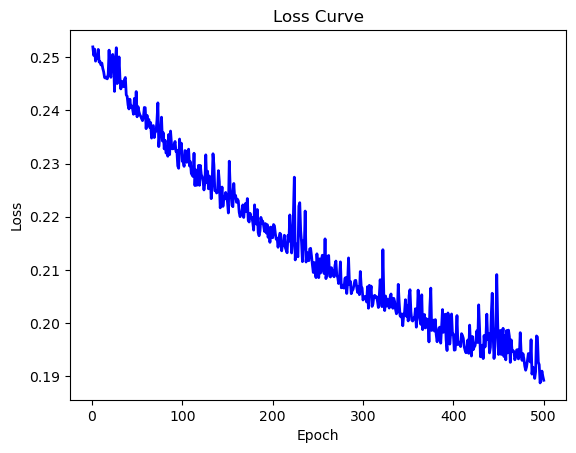

In [8]:
train(opt,layers,x,t,D,epochs=500)

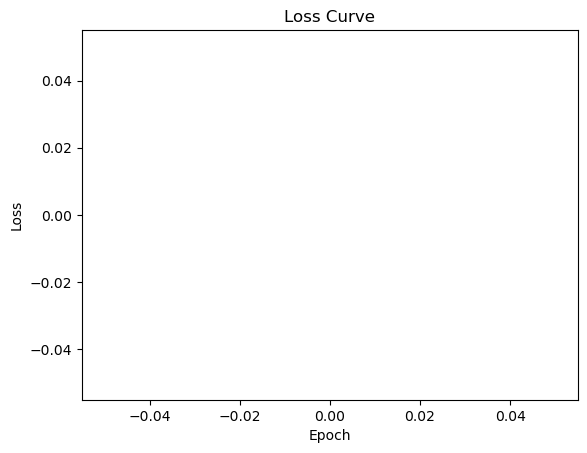

Epoch: 1, Loss: 0.19017944752586785 + 0.0im
Epoch: 2, Loss: 0.18778613212228834 + 0.0im
Epoch: 3, Loss: 0.1901494818515516 + 0.0im
Epoch: 4, Loss: 0.1929035868632245 + 0.0im
Epoch: 5, Loss: 0.19010215151177914 + 0.0im
Epoch: 6, Loss: 0.19108704510608052 + 0.0im
Epoch: 7, Loss: 0.1915867195873451 + 0.0im
Epoch: 8, Loss: 0.19073798739012732 + 0.0im
Epoch: 9, Loss: 0.18933874451887878 + 0.0im
Epoch: 10, Loss: 0.188221426478129 + 0.0im
Epoch: 11, Loss: 0.18975373256316153 + 0.0im
Epoch: 12, Loss: 0.1885761330668373 + 0.0im
Epoch: 13, Loss: 0.19030705398253067 + 0.0im
Epoch: 14, Loss: 0.1905718835108158 + 0.0im
Epoch: 15, Loss: 0.19931655815966096 + 0.0im
Epoch: 16, Loss: 0.19020860275263202 + 0.0im
Epoch: 17, Loss: 0.1891671740929004 + 0.0im
Epoch: 18, Loss: 0.18902489493559785 + 0.0im
Epoch: 19, Loss: 0.18753056360796125 + 0.0im
Epoch: 20, Loss: 0.1909570262724433 + 0.0im
Epoch: 21, Loss: 0.19122387548102734 + 0.0im
Epoch: 22, Loss: 0.1877374279638299 + 0.0im
Epoch: 23, Loss: 0.1852412343

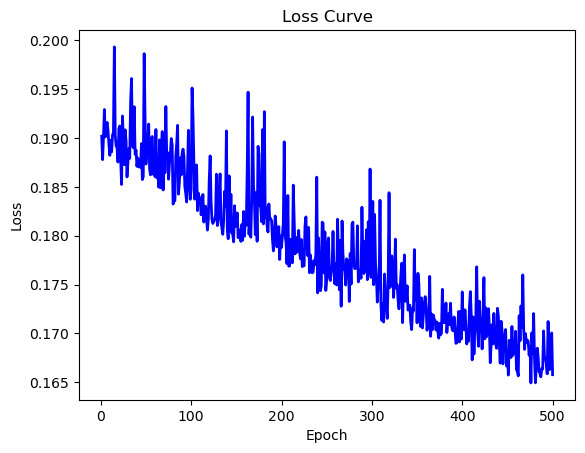

In [9]:
train(opt,layers,x,t,D,epochs=500)